# 03 파일처럼 데이터가 없으면 계속 같은 기준으로 진행. 데이터 예측하기엔 부족.
이걸 보완하는것이 선형회귀(LinearRegression)

In [56]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [57]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [58]:
# 데이터 학습/ 테스트 분리
train_data, test_data, train_label, test_label=train_test_split(perch_length,perch_weight)

In [59]:
train_data= train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3]

array([[18.7],
       [27.5],
       [26.5]])

In [60]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data, train_label)

# 데이터예측
predict = lr.predict(test_data)
print("무게예측:", predict)

# 정확도
score= lr.score(train_data, train_label)
score2= lr.score(test_data, test_label)
print("train정확도:", score)
print("test정확도:", score2)

# 기울기, y 절편의 LinearRegression()을 사용할 때만 나타남.
print('기울기:', lr.coef_)  #예측의 기울기를 알수 있음.
print('y 절편:', lr.intercept_)

무게예측: [  29.15983615  364.10195784  326.04035311  211.85553889  154.76313178
  116.70152704    2.51671283  565.82846296  839.87201707  291.78490884
  383.13276021  839.87201707  801.81041233 -362.87469266]
train정확도: 0.9422431833268627
test정확도: 0.8302449624873621
기울기: [38.06160474]
y 절편: -682.5921724579022


In [61]:
# KNeighborsRegressor() 는 50을 1000으로 100-1000
# 50cm 농어 무게 예측 1132, 100-3034

predict2= lr.predict([[100]])
print("예측무게:",predict2)

예측무게: [3123.56830137]


In [62]:
# 길이를 입력받아, 무게를 예측하고, 산전도 그래프에 표시하시오.
# 농어길이를 입력하세요 (예:52)
# 예측무게는 :1230
# 산전도 그래프에 표시
# 선그래프도 함께 표시

관측되지 않을걸 예상할 수 있지만 
무게가 - 로 나오는 에러가 있음.

예측무게: [-644.53056772]


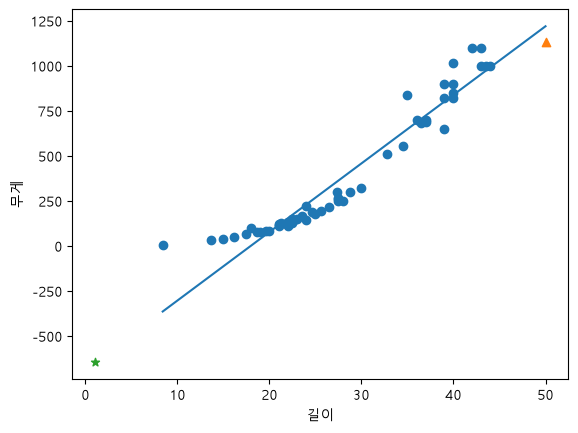

In [63]:
in_data= input('농어길이를 입력하세요 (예:52)')
in_data=float(in_data)
predict = lr.predict([[in_data]])
print("예측무게:",predict)


# 산전도 그래프
plt.scatter(perch_length, perch_weight)
plt.scatter(50,1132,marker='^')
plt.scatter(in_data,predict, marker='*')
# plt.scatter(100,3034,marker='^')

# 기울기 선그래프
plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) 


plt.xlabel('길이')
plt.ylabel('무게')
plt.show()